# **Lab session (Week #8): Feature Importance**

This week we look at different methods to compute feature importance and highlight some of their downsides.

**Why feature importance?**
- Feature importance answers "what is the model relying on?".
- Different methods can give different answers.

**Why does it matter in healthcare?**
- Trust: a clinician won't act on a prediction they cannot sanity-check. "High risk because of flat ST slope and exercise angina" is something a cardiologist can judge.
- Debugging: importance reveals when a model uses something it shouldn't, e.g. a hospital ID, a scanner type, or a leaked variable.
- Regulation: medical AI increasingly needs to be explainable.
- Science: which measurements actually carry the signal and which ones could be dropped from a test?


### **Dataset: Heart Disease** (918 patients, UCI Heart Disease repository)

| Variable | Description |
|---|---|
| AGE | Age in years |
| SEX | M / F |
| CHESTPAINTYPE | ASY · ATA · NAP · TA |
| RESTINGBP | Resting blood pressure (mm Hg) |
| CHOLESTEROL | Serum cholesterol (mg/dl) |
| FASTINGBS | Fasting blood sugar > 120 mg/dl (1 = true) |
| RESTINGECG | Normal · ST · LVH |
| MAXHR | Maximum heart rate achieved |
| EXERCISEANGINA | Exercise-induced angina (Y / N) |
| OLDPEAK | ST depression induced by exercise |
| ST_SLOPE | Up · Flat · Down |
| **HEARTDISEASE** | **1 = positive, 0 = negative** |

### 🔎 1. Import Libraries & preprocessing (Nothing to do)

In [16]:
import os, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn.metrics as metrics

from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

In [17]:
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

df_ = pd.read_csv('heart_failure.csv')
df  = df_.copy()
df.columns = [col.upper() for col in df.columns]

def grab_col_names(dataframe, cat_th=10, car_th=20):
    cat_cols    = [col for col in dataframe.columns if dataframe[col].dtypes == 'O']
    num_but_cat = [col for col in dataframe.columns
                   if dataframe[col].nunique() < cat_th and dataframe[col].dtypes != 'O']
    cat_but_car = [col for col in dataframe.columns
                   if dataframe[col].nunique() > car_th and dataframe[col].dtypes == 'O']
    cat_cols = cat_cols + num_but_cat
    cat_cols = [col for col in cat_cols if col not in cat_but_car]
    num_cols = [col for col in dataframe.columns if dataframe[col].dtypes != 'O']
    num_cols = [col for col in num_cols if col not in num_but_cat]
    print(f'Observations: {dataframe.shape[0]}  |  Variables: {dataframe.shape[1]}')
    print(f'cat_cols: {len(cat_cols)}  |  num_cols: {len(num_cols)}')
    return cat_cols, num_cols, cat_but_car

cat_cols, num_cols, cat_but_car = grab_col_names(df)
print('Numerical:', num_cols)

Observations: 918  |  Variables: 12
cat_cols: 7  |  num_cols: 5
Numerical: ['AGE', 'RESTINGBP', 'CHOLESTEROL', 'MAXHR', 'OLDPEAK']


### 🔎 2. Missing Value Imputation (Nothing to do)

CHOLESTEROL and RESTINGBP contain zeros that are biologically implausible.
We replace them with NaN, then impute each missing value with the **median of similar patients** (same sex and age band).

⚠️ We do **not** impute using `HEARTDISEASE`: a new patient has no label at prediction time, and label-based imputation leaks the answer into the features.

In [18]:
df[['CHOLESTEROL','RESTINGBP']] = df[['CHOLESTEROL','RESTINGBP']].replace(0, np.nan)

# Group patients by sex + age band (information we'd have for any new patient)
age_band = pd.cut(df['AGE'], bins=[0, 45, 55, 65, 120], labels=['<=45', '46-55', '56-65', '>65'])

for col in ['CHOLESTEROL', 'RESTINGBP']:
    group_median = df.groupby([df['SEX'], age_band], observed=True)[col].transform('median')
    df[col] = df[col].fillna(group_median)

# One-hot encode categorical columns
df = pd.get_dummies(df, columns=['SEX', 'EXERCISEANGINA'], drop_first=True, dtype=int)
df = pd.get_dummies(df, columns=['CHESTPAINTYPE', 'RESTINGECG', 'ST_SLOPE'], drop_first=False, dtype=int)

y = df['HEARTDISEASE']
X = df.drop('HEARTDISEASE', axis=1)
print('Remaining NaNs:', X.isna().sum().sum())
print('Features:', list(X.columns))
print('Dataset size:', X.shape)

Remaining NaNs: 0
Features: ['AGE', 'RESTINGBP', 'CHOLESTEROL', 'FASTINGBS', 'MAXHR', 'OLDPEAK', 'SEX_M', 'EXERCISEANGINA_Y', 'CHESTPAINTYPE_ASY', 'CHESTPAINTYPE_ATA', 'CHESTPAINTYPE_NAP', 'CHESTPAINTYPE_TA', 'RESTINGECG_LVH', 'RESTINGECG_Normal', 'RESTINGECG_ST', 'ST_SLOPE_Down', 'ST_SLOPE_Flat', 'ST_SLOPE_Up']
Dataset size: (918, 18)


## 🔎 3. Feature Importance

### 🦏 3.1 Logistic Regression

https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

Accuracy: 0.8623188405797102
F1-score: 0.8716216216216216


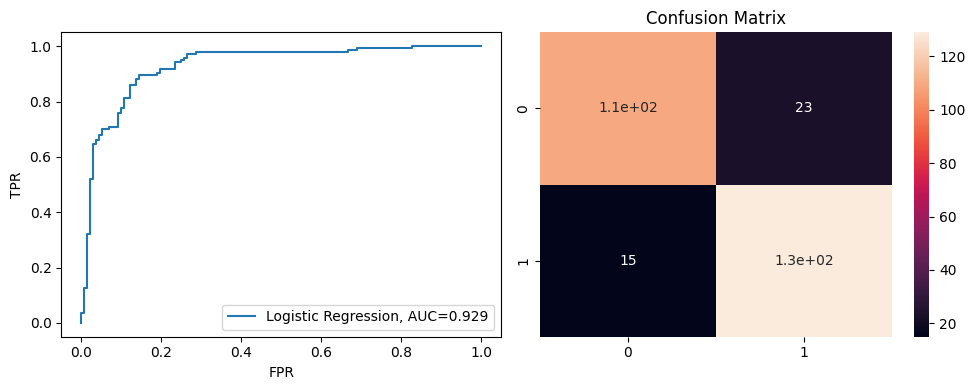

In [19]:
from sklearn.metrics import f1_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=17)

lr_model = LogisticRegression(max_iter=1000).fit(X_train, y_train)
y_pred   = lr_model.predict(X_test)
print('Accuracy:', accuracy_score(y_test, y_pred))
print('F1-score:', f1_score(y_test, y_pred))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
probs = lr_model.predict_proba(X_test)
fpr_v, tpr_v, _ = metrics.roc_curve(y_test, probs[:,1])
auc = metrics.roc_auc_score(y_test, probs[:,1])
axes[0].plot(fpr_v, tpr_v, label=f'Logistic Regression, AUC={auc:.3f}')
axes[0].legend(loc=4); axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, ax=axes[1])
axes[1].set_title('Confusion Matrix')
fig.tight_layout(); plt.show()

**Why scale?** Logistic regression coefficients are only directly comparable if features are on the same scale. Without scaling, a large coefficient might just mean the feature has small numeric values, not that it matters more.

**Why scale *after* the split?** If we fit the scaler on the whole dataset before splitting, the test-set statistics (mean, std) leak into the training process and the model indirectly 'sees' test data.
- `fit` only on `X_train`, then `transform` both.

❗ Scale `X_train` and `X_test` using `StandardScaler`. Fit on training data only, then transform both sets.

*Hint:* https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

## Write your code here:
## X_train_sc = scaler.fit_transform(????)
## X_test_sc  = scaler.transform(?????)

# Convert back to DataFrame so column names are preserved for the coefficient plot
X_train_sc = pd.DataFrame(X_train_sc, columns=X_train.columns, index=X_train.index)
X_test_sc  = pd.DataFrame(X_test_sc,  columns=X_test.columns,  index=X_test.index)

lr_model = LogisticRegression(max_iter=1000).fit(X_train_sc, y_train)
y_pred   = lr_model.predict(X_test_sc)
print('Accuracy (scaled LR):', accuracy_score(y_test, y_pred))
print('F1-score (scaled LR):', f1_score(y_test, y_pred))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
probs = lr_model.predict_proba(X_test_sc)
fpr_v, tpr_v, _ = metrics.roc_curve(y_test, probs[:,1])
auc = metrics.roc_auc_score(y_test, probs[:,1])
axes[0].plot(fpr_v, tpr_v, label=f'Logistic Regression (scaled), AUC={auc:.3f}')
axes[0].legend(loc=4); axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, ax=axes[1])
axes[1].set_title('Confusion Matrix')
fig.tight_layout(); plt.show()

❗ Plot the **coefficients** of the scaled logistic regression model using the helper function below (or create your own).

❗ Which feature has the largest positive coefficient? Which has the most negative? Because features are now standardised, coefficients are comparable. A larger absolute value means a stronger effect.


In [ ]:
def plot_importance(model, feature_names, num=len(X.columns)):
    feature_imp = pd.DataFrame({'Value': model.coef_[0], 'Feature': feature_names})
    plt.figure(figsize=(8, 6))
    sns.barplot(x='Value', y='Feature',
                data=feature_imp.sort_values(by='Value', ascending=False).head(num))
    plt.title('Logistic Regression Coefficients (standardised features)')
    plt.tight_layout(); plt.show()

# Your code here...

### 🌴 3.2 Random Forest — Mean Decrease in Impurity (MDI)

Train and evaluate a Random Forest model.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=17)

rf_model = # Your code here...
y_pred   = # Your code here...
print('RF Accuracy:', accuracy_score(y_test, y_pred))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
probs = rf_model.predict_proba(X_test)
fpr_v, tpr_v, _ = metrics.roc_curve(y_test, probs[:,1])
auc = metrics.roc_auc_score(y_test, probs[:,1])
axes[0].plot(fpr_v, tpr_v, label=f'Random Forest, AUC={auc:.3f}')
axes[0].legend(loc=4); axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, ax=axes[1])
axes[1].set_title('Confusion Matrix')
fig.tight_layout(); plt.show()

**Mean Decrease in Impurity (MDI / Gini Importance)** approximates each feature's importance as the weighted sum of impurity reductions it causes across all splits and all trees.

❗ Compute the MDI of the trained RF model.

*Hint:* Use the `feature_importances_` attribute: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

❗ Which feature is the most important according to MDI?

In [ ]:
from sklearn import tree

plt.figure(figsize=(20, 6))
_ = tree.plot_tree(rf_model.estimators_[0], feature_names=X_train.columns,
                   class_names=['No Disease','Disease'], filled=True, max_depth=3)
plt.show()

feature_names = X_train.columns

importances = # Your code here...

forest_importances = pd.Series(importances, index=feature_names).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
forest_importances.plot.barh(ax=ax, color='purple')
ax.set_title('Feature Importance — Mean Decrease in Impurity (MDI)')
fig.tight_layout(); plt.show()

🎲 **Random features**

MDI is computed on training data, so it can overfit. It also tends to inflate the importance of **high-cardinality** numerical features (many unique values).

See: https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance.html

❗ Add a feature **RANDOM_NUM** with random real values (high cardinality) to `X_modified`.

❗ **RANDOM_CAT** (3 integer values, low cardinality) is already added for you.

❗ Retrain and evaluate. Does accuracy change meaningfully?

In [ ]:
X_modified = X.copy()
rng = np.random.RandomState(seed=42)

## Write your code here — add RANDOM_NUM using rng
## X_modified['RANDOM_NUM'] = ....

X_modified['RANDOM_CAT'] = rng.randint(3, size=X.shape[0])

X_train_rand, X_test_rand, y_train_rand, y_test_rand = train_test_split(
    X_modified, y, test_size=0.30, random_state=17)

rf_model_rand = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1
                                       ).fit(X_train_rand, y_train_rand)
y_pred_rand = rf_model_rand.predict(X_test_rand)
print('Accuracy (with random features):', accuracy_score(y_test_rand, y_pred_rand))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
probs = rf_model_rand.predict_proba(X_test_rand)
fpr_v, tpr_v, _ = metrics.roc_curve(y_test_rand, probs[:,1])
auc = metrics.roc_auc_score(y_test_rand, probs[:,1])
axes[0].plot(fpr_v, tpr_v, label=f'Random Forest, AUC={auc:.3f}')
axes[0].legend(loc=4)
sns.heatmap(confusion_matrix(y_test_rand, y_pred_rand), annot=True, ax=axes[1])
fig.tight_layout(); plt.show()

❗ Plot the MDI importances. What do you notice about RANDOM_NUM vs RANDOM_CAT?

In [ ]:
feature_names_rand = X_train_rand.columns
mdi_importances = pd.Series(
    rf_model_rand.feature_importances_, index=feature_names_rand
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
## Write your code here — plot mdi_importances as a horizontal bar chart
## .......
ax.set_title('Feature importances using MDI (with random features)')
fig.tight_layout(); plt.show()

### 🎲 3.3 Permutation Importance

Permutation feature importance measures the decrease in model accuracy after **randomly shuffling** one feature's values, breaking the relationship between that feature and the target. Unlike MDI, this is computed on the **test set**.

*Read more:* https://christophm.github.io/interpretable-ml-book/feature-importance.html

❗ Compute the permutation importance on the **test set** using sklearn.

*Hint:* https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html

❗ Does the ranking agree with MDI? Which features change rank?

In [ ]:
# Same split and model as the MDI section (3.2), so only the importance method differs
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=17)
rf_model = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1
                                  ).fit(X_train, y_train)
print('RF Accuracy:', accuracy_score(y_test, rf_model.predict(X_test)))

In [ ]:
from sklearn.inspection import permutation_importance

feature_names = X_train.columns

## Compute permutation importance on the TEST set !!!! Write your code here:
## result = ....

importances_pi = pd.DataFrame(result.importances.T, columns=feature_names)

fig, ax = plt.subplots(figsize=(10, 5))
importances_pi.plot.box(vert=False, whis=10, ax=ax)
ax.set_title('Permutation Importances (test set)')
ax.axvline(x=0, color='k', linestyle='--')
ax.set_xlabel('Decrease in accuracy score')
fig.tight_layout(); plt.show()

### 👯 3.4 Correlated / Duplicated Features

When two features carry the same information, permutation importance **splits** the importance between them — each one looks less important than it really is, because shuffling either one alone only partially breaks the signal.

❗ Add **ST_SLOPE_Up_COPY**, an exact copy of `ST_SLOPE_Up` (the most important feature from 3.3), to `X_duplicate`.

❗ Retrain the RF and recompute permutation importance. How does the importance of `ST_SLOPE_Up` change? What does `ST_SLOPE_Up_COPY` get?

❗ What does this imply about interpreting feature importance in datasets with correlated features (e.g. BMI and weight, or age and years of experience)?

In [ ]:
X_duplicate = X.copy()

## Write your code here — add ST_SLOPE_Up_COPY as an exact copy of ST_SLOPE_Up
## X_duplicate['ST_SLOPE_Up_COPY'] = ...

X_train_dup, X_test_dup, y_train_dup, y_test_dup = train_test_split(
    X_duplicate, y, test_size=0.30, random_state=17)

rf_model_dup = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1
                                      ).fit(X_train_dup, y_train_dup)
print('Accuracy (with duplicate):', accuracy_score(y_test_dup, rf_model_dup.predict(X_test_dup)))

## Compute permutation importance — same as Section 3.3  !!!! Write your code here:
## result_dup = ....

importances_dup = pd.DataFrame(result_dup.importances.T, columns=X_train_dup.columns)

fig, ax = plt.subplots(figsize=(10, 6))
importances_dup.plot.box(vert=False, whis=10, ax=ax)
ax.set_title('Permutation Importances — with ST_SLOPE_Up duplicate')
ax.axvline(x=0, color='k', linestyle='--')
ax.set_xlabel('Decrease in accuracy score')
fig.tight_layout(); plt.show()

## 🌟 4. SHAP — SHapley Additive exPlanations

SHAP assigns each feature a **contribution** to a specific prediction, grounded in game theory (Shapley values).
Unlike MDI or permutation importance, SHAP explains **individual predictions** as well as global behaviour.

*Read more:* https://shap.readthedocs.io/en/latest/

We use `shap.TreeExplainer`, which is fast and exact for tree-based models like Random Forest.

❗ Create a `shap.TreeExplainer` for `rf_model` and compute `shap_values` on the test set.

*Hint:* In SHAP ≥ 0.42, `explainer.shap_values(X_test)` returns a 3D array of shape `(n_samples, n_features, 2)`.  
Use `shap_values[:, :, 1]` to get the class-1 (Heart Disease) contributions.

In [ ]:
!pip install shap -q
import shap

# Reset to clean features (no duplicate)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=17)
rf_model = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1
                                  ).fit(X_train, y_train)

## Write your code here:
## 1. Create the SHAP explainer
## explainer = shap.TreeExplainer(????)

## 2. Compute SHAP values for the test set
## shap_values = ????


## 3. Extract class-1 contributions  (shape: n_samples × n_features)
## shap_values_1 = shap_values[:, :, 1]

print('SHAP values shape (class 1):', shap_values_1.shape)

❗ Run the cells below to visualise **global** feature importance with SHAP.

The **bar plot** shows the mean absolute SHAP value for each feature — how much, on average, each feature moves the prediction.

The **beeswarm plot** goes further: each dot is one test patient. Colour = feature value (red = high, blue = low). Position on x-axis = how much it pushed the prediction towards 1 (Heart Disease) or 0.

❗ Do the top features agree with MDI and permutation importance? What new information does the beeswarm add?

In [ ]:
# Global bar chart — mean |SHAP| per feature
shap.summary_plot(shap_values_1, X_test, plot_type='bar',
                  feature_names=list(X_test.columns), show=True)

In [ ]:
# Beeswarm — distribution of SHAP values across all test patients
shap.summary_plot(shap_values_1, X_test, feature_names=list(X_test.columns), show=True)

❗ Pick **one test patient** (choose any index) and plot a **force plot** to see which features pushed the model towards or away from predicting Heart Disease.

❗ Then find a **misclassified patient** (true label ≠ predicted label) and explain their prediction. Can you see from the force plot *why* the model got it wrong?

In [ ]:
y_pred_test = rf_model.predict(X_test)
wrong_idx   = np.where(y_pred_test != y_test.values)[0][0]
print(f'Misclassified patient — index {wrong_idx}: '
      f'true={y_test.values[wrong_idx]}, pred={y_pred_test[wrong_idx]}')

## Write your code here — plot a force plot for a patient of your choice:
## shap.initjs()   # needed in Colab/Jupyter
## shap.force_plot(explainer.expected_value[1], shap_values_1[????], X_test.iloc[????],
##                 feature_names=list(X_test.columns), matplotlib=True)

---
## ⚙️ [OPTIONAL] Drop-Column Feature Importance

An alternative to permutation importance: train the model **with all features**, then remove each feature one by one and measure the drop in accuracy.
A large drop means the feature was important.

This is slower than permutation importance (requires a full refit per feature) but avoids the unrealistic data combinations that permutation can create.

❗ Complete the function below and compare the ranking to permutation importance from Section 3.3.

⚠️ With a single test set of 276 patients, one patient = 0.36% accuracy. Small differences (and even negative importances) are mostly noise.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=17)
rf_model = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1
                                  ).fit(X_train, y_train)
print('RF Accuracy:', accuracy_score(y_test, rf_model.predict(X_test)))

In [ ]:
def drop_features(features, model=RandomForestClassifier(n_estimators=200, random_state=78),
                  X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test):

    initial_model    = model.fit(X_train, y_train)
    initial_accuracy = accuracy_score(initial_model.predict(X_test), y_test)

    drop_importances = []
    for feature in features:
        # !!! Write your code here:
        # Remove the feature from both train and test sets
        ## X_train_drop = ??
        ## X_test_drop  = ??

        rf_model_drop = model.fit(X_train_drop, y_train)
        drop_accuracy = accuracy_score(rf_model_drop.predict(X_test_drop), y_test)

        # Importance = how much accuracy we lose
        # !!! Write your code here:
        ## drop_importance = ???

        drop_importances.append(drop_importance)

    return pd.Series(drop_importances, index=features).sort_values(ascending=True)


drop_imp = drop_features(X_train.columns)

fig, ax = plt.subplots(figsize=(8, 6))
drop_imp.plot.barh(ax=ax, color='green')
ax.set_title('Drop-column Feature Importance')
fig.tight_layout(); plt.show()